In [1]:
# IMPORTS
from graph import app 
import pandas as pd
import os
from tqdm.auto import tqdm
import torch
import time 
from Configuration.models import models #import models to evaluate
from dotenv import load_dotenv
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
from langchain_neo4j import Neo4jGraph  # for schema
from langchain_ollama import ChatOllama

In [2]:
import pandas as pd
import os
import shutil
import ast

files = {
    '8B_Baseline': 'Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_llama3_1_8b_baseline.xlsx',
    '8B_Gen_Helper_History': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama3_1_8b_gen_helper_history.xlsx',
    '8B_Gen_Helper_Trajectory': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama3_1_8b_gen_helper_traj.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_llama3_1_8b_history_only.xlsx',
    '8B_Trajectory_History': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_HISTORY/100_test_llama3_1_8b_traj_history.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_ONLY/100_test_llama3_1_8b_traj_only.xlsx',
    '8B_Memory_All_In': 'Outputs_Evaluation/New_Movies_Experiment/MEMORY_ALL_IN/100_test_llama3_1_8b_mem_all_in.xlsx',

    '7B_Baseline': 'Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_qwen_2.5_7b_baseline.xlsx',
    '7B_Gen_Helper_History': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_qwen_2.5_7b_gen_helper_history.xlsx',
    '7B_Gen_Helper_Trajectory': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_qwen_2.5_7b_gen_helper_traj.xlsx',
    '7B_History_Only': 'Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_qwen_2.5_7b_history_only.xlsx',
    '7B_Trajectory_History': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_HISTORY/100_test_qwen_2.5_7b_traj_history.xlsx',
    '7B_Trajectory_Only': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_ONLY/100_test_qwen_2.5_7b_traj_only.xlsx',
    '7B_Memory_All_In': 'Outputs_Evaluation/New_Movies_Experiment/MEMORY_ALL_IN/100_test_qwen_2.5_7b_mem_all_in.xlsx',

    '3B_Baseline': 'Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_llama3_2_3b_baseline.xlsx',
    '3B_Gen_Helper_History': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama3_2_3b_gen_helper_history.xlsx',
    '3B_Gen_Helper_Trajectory': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama3_2_3b_gen_helper_traj.xlsx',
    '3B_History_Only': 'Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_llama3_2_3b_history_only.xlsx',
    '3B_Trajectory_History': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_HISTORY/100_test_llama3_2_3b_traj_history.xlsx',
    '3B_Trajectory_Only': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_ONLY/100_test_llama3_2_3b_traj_only.xlsx',
    '3B_Memory_All_In': 'Outputs_Evaluation/New_Movies_Experiment/MEMORY_ALL_IN/100_test_llama3_2_3b_mem_all_in.xlsx'
}

def count_corrector_iterations(path):
    if pd.isna(path):
        return 0

    if isinstance(path, list):
        return path.count('cypher_corrector')

    try:
        parsed_path = ast.literal_eval(str(path))
        if isinstance(parsed_path, list):
            return parsed_path.count('cypher_corrector')
    except (ValueError, SyntaxError):
        pass

    return str(path).count('cypher_corrector')


for config_name, file_path in files.items():
    print(f"\nProcessing {config_name}...")

    if not os.path.exists(file_path):
        print(f"  File not found: {file_path}")
        continue

    df = pd.read_excel(file_path)

    if 'path' not in df.columns:
        print("  Skipped: no 'path' column.")
        continue

    # Backup original file only if backup does not already exist
    backup_path = file_path.replace('.xlsx', '_backup.xlsx')

    if not os.path.exists(backup_path):
        shutil.copy2(file_path, backup_path)
        print(f"  Backup created: {backup_path}")
    else:
        print("  Backup already exists, not overwritten.")

    # Save old values temporarily so we can compare
    if 'total_iterations' in df.columns:
        old_iterations = df['total_iterations'].copy()
    else:
        old_iterations = pd.Series([None] * len(df))

    # Recalculate total_iterations ONLY from cypher_corrector frequency
    df['total_iterations'] = df['path'].apply(count_corrector_iterations)

    # Overwrite original Excel
    df.to_excel(file_path, index=False)

    changed_rows = (
        pd.to_numeric(old_iterations, errors='coerce')
        != pd.to_numeric(df['total_iterations'], errors='coerce')
    ).sum()

    print(f"  Corrected rows: {changed_rows}")
    print(f"  Min iterations: {df['total_iterations'].min()}")
    print(f"  Max iterations: {df['total_iterations'].max()}")
    print(f"  Saved: {file_path}")

print("\nDone. All available files were corrected.")


Processing 8B_Baseline...
  Backup already exists, not overwritten.
  Corrected rows: 0
  Min iterations: 0
  Max iterations: 10
  Saved: Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_llama3_1_8b_baseline.xlsx

Processing 8B_Gen_Helper_History...
  Backup already exists, not overwritten.
  Corrected rows: 0
  Min iterations: 0
  Max iterations: 10
  Saved: Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama3_1_8b_gen_helper_history.xlsx

Processing 8B_Gen_Helper_Trajectory...
  Backup already exists, not overwritten.
  Corrected rows: 0
  Min iterations: 0
  Max iterations: 10
  Saved: Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama3_1_8b_gen_helper_traj.xlsx

Processing 8B_History_Only...
  Backup already exists, not overwritten.
  Corrected rows: 0
  Min iterations: 0
  Max iterations: 10
  Saved: Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_llama3_1_8b_history_only.xlsx

Processing 8B_Trajectory_History..

In [ ]:
import pandas as pd
import os
import ast
from utils.Evaluation.calculate_metrics import calculate_scores_benchmark_without_original_validation

files = {
    '8B_Baseline': 'Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_llama3_1_8b_baseline.xlsx',
    '8B_Gen_Helper_History': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama3_1_8b_gen_helper_history.xlsx',
    '8B_Gen_Helper_Trajectory': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama3_1_8b_gen_helper_traj.xlsx',
    '8B_History_Only': 'Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_llama3_1_8b_history_only.xlsx',
    '8B_Trajectory_History': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_HISTORY/100_test_llama3_1_8b_traj_history.xlsx',
    '8B_Trajectory_Only': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_ONLY/100_test_llama3_1_8b_traj_only.xlsx',
    '8B_Memory_All_In': 'Outputs_Evaluation/New_Movies_Experiment/MEMORY_ALL_IN/100_test_llama3_1_8b_mem_all_in.xlsx',

    '7B_Baseline': 'Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_qwen_2.5_7b_baseline.xlsx',
    '7B_Gen_Helper_History': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_qwen_2.5_7b_gen_helper_history.xlsx',
    '7B_Gen_Helper_Trajectory': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_qwen_2.5_7b_gen_helper_traj.xlsx',
    '7B_History_Only': 'Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_qwen_2.5_7b_history_only.xlsx',
    '7B_Trajectory_History': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_HISTORY/100_test_qwen_2.5_7b_traj_history.xlsx',
    '7B_Trajectory_Only': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_ONLY/100_test_qwen_2.5_7b_traj_only.xlsx',
    '7B_Memory_All_In': 'Outputs_Evaluation/New_Movies_Experiment/MEMORY_ALL_IN/100_test_qwen_2.5_7b_mem_all_in.xlsx',

    '3B_Baseline': 'Outputs_Evaluation/New_Movies_Experiment/BASELINE/100_test_llama3_2_3b_baseline.xlsx',
    '3B_Gen_Helper_History': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_HISTORY/100_test_llama3_2_3b_gen_helper_history.xlsx',
    '3B_Gen_Helper_Trajectory': 'Outputs_Evaluation/New_Movies_Experiment/GEN_HELPER_TRAJ/100_test_llama3_2_3b_gen_helper_traj.xlsx',
    '3B_History_Only': 'Outputs_Evaluation/New_Movies_Experiment/HISTORY_ONLY/100_test_llama3_2_3b_history_only.xlsx',
    '3B_Trajectory_History': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_HISTORY/100_test_llama3_2_3b_traj_history.xlsx',
    '3B_Trajectory_Only': 'Outputs_Evaluation/New_Movies_Experiment/TRAJECTORY_ONLY/100_test_llama3_2_3b_traj_only.xlsx',
    '3B_Memory_All_In': 'Outputs_Evaluation/New_Movies_Experiment/MEMORY_ALL_IN/100_test_llama3_2_3b_mem_all_in.xlsx'
}

model_mapping = {
    '8B': 'llama3_1_8b',
    '7B': 'qwen_2.5_7b',
    '3B': 'llama3_2_3b'
}

summary_results = []

def extract_iterations(history_value):
    if pd.isna(history_value) or str(history_value).strip() in ['', 'None', '[]']:
        return 1
    try:
        parsed = ast.literal_eval(str(history_value))
        return len(parsed) if isinstance(parsed, list) else 1
    except (ValueError, SyntaxError):
        return 1

for config_name, file_path in files.items():
    print(f"\n--- Processing: {config_name} ---")

    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue

    # Get correct model automatically from 8B / 7B / 3B prefix
    model_key = config_name.split('_')[0]
    model_name = model_mapping[model_key]

    workflow_df = pd.read_excel(file_path).astype(object)

    evaluated_df = calculate_scores_benchmark_without_original_validation(
        model_name=model_name,
        model_name_pkl=f'{config_name}_evaluated',
        dataset='New_Movies_Experiment_Metrics',
        input_df=workflow_df
    )

    if 'total_iterations' not in evaluated_df.columns:
        if 'cypher_errors_history' in evaluated_df.columns:
            evaluated_df['total_iterations'] = evaluated_df['cypher_errors_history'].apply(extract_iterations)
        else:
            evaluated_df['total_iterations'] = 1

    queries_count = len(evaluated_df)
    pass_score = evaluated_df['Pass@1 Output'].fillna(False).astype(bool).sum()
    avg_loops = evaluated_df['total_iterations'].mean()

    summary_results.append({
        'Configuration': config_name,
        'Queries': queries_count,
        'Pass@1 (%)': round((pass_score / queries_count) * 100, 2),
        'Mean Iterations': round(avg_loops, 2)
    })

print("\n" + "=" * 60)
print("FINAL BENCHMARK COMPARISON TABLE")
print("=" * 60)
print(pd.DataFrame(summary_results).to_string(index=False))
print("=" * 60)

# START OF DIAGRAMS 

In [20]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

# ============================================================
# FILES
# ============================================================

files = {
    '8B': {
        'Baseline': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'New_Movies_Experiment_Metrics/llama3_1_8b/8B_Memory_All_In_evaluated.xlsx'
    },
    '7B': {
        'Baseline': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'New_Movies_Experiment_Metrics/qwen_2.5_7b/7B_Memory_All_In_evaluated.xlsx'
    },
    '3B': {
        'Baseline': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_Baseline_evaluated.xlsx',
        'Gen_Helper_History': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_Gen_Helper_History_evaluated.xlsx',
        'Gen_Helper_Trajectory': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_Gen_Helper_Trajectory_evaluated.xlsx',
        'History_Only': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_History_Only_evaluated.xlsx',
        'Trajectory_History': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_Trajectory_History_evaluated.xlsx',
        'Trajectory_Only': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_Trajectory_Only_evaluated.xlsx',
        'All_In': 'New_Movies_Experiment_Metrics/llama3_2_3b/3B_Memory_All_In_evaluated.xlsx'
    }
}

model_names = {
    '8B': 'Llama-3.1-8B-Instruct',
    '7B': 'Qwen-2.5-7B-Instruct',
    '3B': 'Llama-3.2-3B-Instruct'
}

config_names = {
    'Baseline': 'Baseline',
    'Gen_Helper_History': 'Gen Helper\n+ History',
    'Gen_Helper_Trajectory': 'Gen Helper\n+ Trajectory',
    'History_Only': 'History\nOnly',
    'Trajectory_History': 'Trajectory\n+ History',
    'Trajectory_Only': 'Trajectory\nOnly',
    'All_In': 'CyVerACT\nAll-In'
}

model_order = ['8B', '7B', '3B']

config_order = [
    'Baseline',
    'Gen_Helper_History',
    'Gen_Helper_Trajectory',
    'History_Only',
    'Trajectory_History',
    'Trajectory_Only',
    'All_In'
]

# ============================================================
# COLORS
# ============================================================

COLOR_FILTERED = '#2A9D8F'
COLOR_FULL = '#4A90E2'
COLOR_UNAVAILABLE = '#E32322'
COLOR_FILTERED_FAIL = '#E9C46A'
COLOR_FULL_FAIL = '#F4A261'

# ============================================================
# HELPERS
# ============================================================

def normalize_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    if pd.api.types.is_numeric_dtype(series):
        return series.fillna(0).ne(0)
    s = series.fillna('').astype(str).str.strip().str.lower()
    return s.isin({'true', '1', 'yes', 'y', 't'})

def path_to_string(path):
    if path is None:
        return ''
    if isinstance(path, (list, tuple)):
        return ' -> '.join(str(x) for x in path)
    if pd.isna(path):
        return ''
    return str(path)

def get_schema_phase(row):
    if not row['final_kg_valid']:
        return 'Unavailable'

    if row['full_schema_valid']:
        return 'Full'

    return 'Filtered'

def count_local_iteration(row):
    phase = row['SchemaPhase']
    path = path_to_string(row['path'])

    if phase == 'Unavailable':
        return np.nan

    if phase == 'Filtered':
        filtered_path = path.split('schema_retriever', 1)[0]
        return filtered_path.count('cypher_corrector')

    if phase == 'Full':
        if 'schema_retriever' in path:
            full_path = path.split('schema_retriever', 1)[1]
            return full_path.count('cypher_corrector')

        return max(0, path.count('cypher_corrector') - 5)

    return np.nan

def get_iteration_color(base_color, iteration, max_iteration=5):
    rgb = np.array(mcolors.to_rgb(base_color))
    lighten = (int(iteration) / max_iteration) * 0.55
    new_rgb = rgb * (1 - lighten) + np.ones(3) * lighten
    return mcolors.to_hex(new_rgb)

# Only show outer percentages when slice >= 2%
def outer_autopct(pct):
    return f'{pct:.0f}%' if pct >= 2 else ''

# ============================================================
# LOAD DATA
# ============================================================

dfs = {}

for model_key, configs in files.items():
    dfs[model_key] = {}

    for config_name, path in configs.items():
        if not os.path.exists(path):
            print(f'File not found: {path}')
            continue

        df = pd.read_excel(path)

        df['final_kg_valid'] = normalize_bool(
            df['is_KG_Valid_correct']
        )

        df['full_schema_valid'] = normalize_bool(
            df['is_KG_Valid_correct_with_full_schema']
        )

        df['SchemaPhase'] = df.apply(
            get_schema_phase,
            axis=1
        )

        df['Iteration'] = df.apply(
            count_local_iteration,
            axis=1
        )

        dfs[model_key][config_name] = df

os.makedirs('Figures', exist_ok=True)

Difficulty                    Easy  Medium  Hard
Model Configuration                             
3B    All_In                  66.7    64.6  54.8
      Baseline                52.4    45.8  35.5
      Gen_Helper_History      47.6    50.0  45.2
      Gen_Helper_Trajectory   66.7    70.8  54.8
      History_Only            61.9    47.9  48.4
      Trajectory_History      61.9    50.0  54.8
      Trajectory_Only         61.9    64.6  51.6
7B    All_In                  90.5    87.5  71.0
      Baseline                81.0    81.2  54.8
      Gen_Helper_History      85.7    81.2  61.3
      Gen_Helper_Trajectory   95.2    83.3  71.0
      History_Only            81.0    81.2  54.8
      Trajectory_History      95.2    81.2  67.7
      Trajectory_Only        100.0    81.2  67.7
8B    All_In                  95.2    85.4  61.3
      Baseline                90.5    89.6  83.9
      Gen_Helper_History      95.2    93.8  71.0
      Gen_Helper_Trajectory   95.2    89.6  90.3
      History_Only            85.7    95.8  67.7
      Trajectory_History      95.2    87.5  71.0
      Trajectory_Only         95.2    93.8  77.4

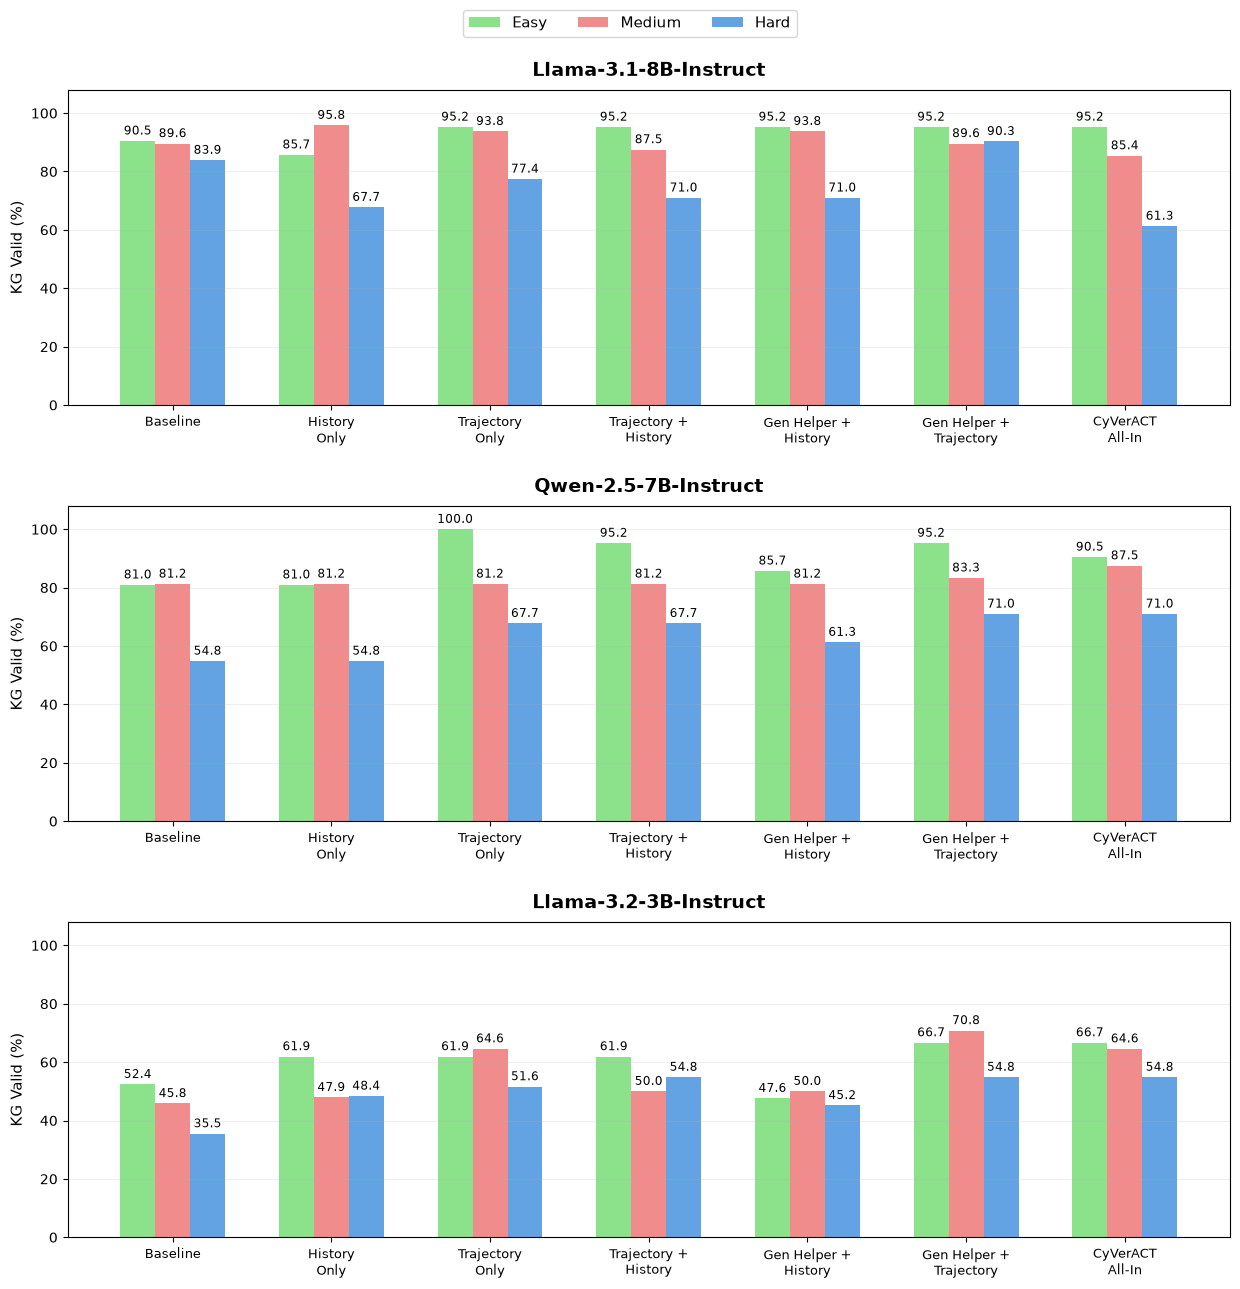

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
import os

def normalize_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    if pd.api.types.is_numeric_dtype(series):
        return series.fillna(0).ne(0)
    s = series.fillna('').astype(str).str.strip().str.lower()
    return s.isin({'true', '1', 'yes', 'y', 't'})

def categorize_complexity(query):
    query_upper = str(query).upper()
    hard_patterns = r'\b(COLLECT|FILTER|UNWIND|WITH|FOREACH|REDUCE|CALL|YIELD|APOC)\b'
    medium_patterns = r'\b(ORDER BY|LIMIT|SKIP|COUNT|DISTINCT|EXISTS|IN|AND|OR|MIN|MAX|AVG|SUM)\b'

    if re.search(hard_patterns, query_upper):
        return 'Hard'
    elif re.search(medium_patterns, query_upper):
        return 'Medium'
    else:
        return 'Easy'

difficulty_order = ['Easy', 'Medium', 'Hard']

difficulty_colors = {
    'Easy': '#8BE28B',
    'Medium': '#F08C8C',
    'Hard': '#64A3E3'
}

plot_config_order = [
    'Baseline',
    'History_Only',
    'Trajectory_Only',
    'Trajectory_History',
    'Gen_Helper_History',
    'Gen_Helper_Trajectory',
    'All_In'
]

plot_config_labels = {
    'Baseline': 'Baseline',
    'History_Only': 'History\nOnly',
    'Trajectory_Only': 'Trajectory\nOnly',
    'Trajectory_History': 'Trajectory +\nHistory',
    'Gen_Helper_History': 'Gen Helper +\nHistory',
    'Gen_Helper_Trajectory': 'Gen Helper +\nTrajectory',
    'All_In': 'CyVerACT\nAll-In'
}

rows = []

for model_key in model_order:
    for config_name in plot_config_order:
        file_path = files[model_key][config_name]
        df = pd.read_excel(file_path)

        df['Difficulty'] = df['cypher'].apply(categorize_complexity)

        # Final offline KG Valid = source of truth
        df['final_kg_valid'] = normalize_bool(df['is_KG_Valid_correct'])

        for difficulty in difficulty_order:
            subset = df[df['Difficulty'] == difficulty]

            rows.append({
                'Model': model_key,
                'Configuration': config_name,
                'Difficulty': difficulty,
                'KG Valid (%)': subset['final_kg_valid'].mean() * 100
            })

difficulty_results = pd.DataFrame(rows)

summary_table = difficulty_results.pivot_table(
    index=['Model', 'Configuration'],
    columns='Difficulty',
    values='KG Valid (%)'
).reindex(columns=difficulty_order)

display(summary_table.round(1))

fig, axes = plt.subplots(3, 1, figsize=(15, 13.5), sharey=True)

bar_width = 0.22
x = np.arange(len(plot_config_order))

offsets = {
    'Easy': -bar_width,
    'Medium': 0,
    'Hard': bar_width
}

for ax, model_key in zip(axes, model_order):
    model_df = difficulty_results[difficulty_results['Model'] == model_key]

    for difficulty in difficulty_order:
        values = []

        for config_name in plot_config_order:
            result = model_df[
                (model_df['Configuration'] == config_name) &
                (model_df['Difficulty'] == difficulty)
            ]
            values.append(result['KG Valid (%)'].iloc[0])

        bars = ax.bar(
            x + offsets[difficulty],
            values,
            width=bar_width,
            label=difficulty,
            color=difficulty_colors[difficulty]
        )

        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width()/2,
                value + 1.2,
                f'{value:.1f}',
                ha='center',
                va='bottom',
                fontsize=8.5
            )

    ax.set_title(
        model_names[model_key],
        fontsize=14,
        fontweight='bold',
        pad=10
    )

    ax.set_ylabel('KG Valid (%)', fontsize=11)
    ax.set_ylim(0, 108)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [plot_config_labels[c] for c in plot_config_order],
        fontsize=9
    )

    ax.tick_params(axis='y', labelsize=10)
    ax.grid(axis='y', alpha=0.20)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    ncol=3,
    bbox_to_anchor=(0.5, 0.985),
    fontsize=11,
    frameon=True
)

plt.subplots_adjust(
    top=0.92,
    bottom=0.07,
    hspace=0.32
)

plt.savefig('kg_valid_by_difficulty.pdf', bbox_inches='tight')
plt.savefig('kg_valid_by_difficulty.png', dpi=200, bbox_inches='tight')

plt.show()

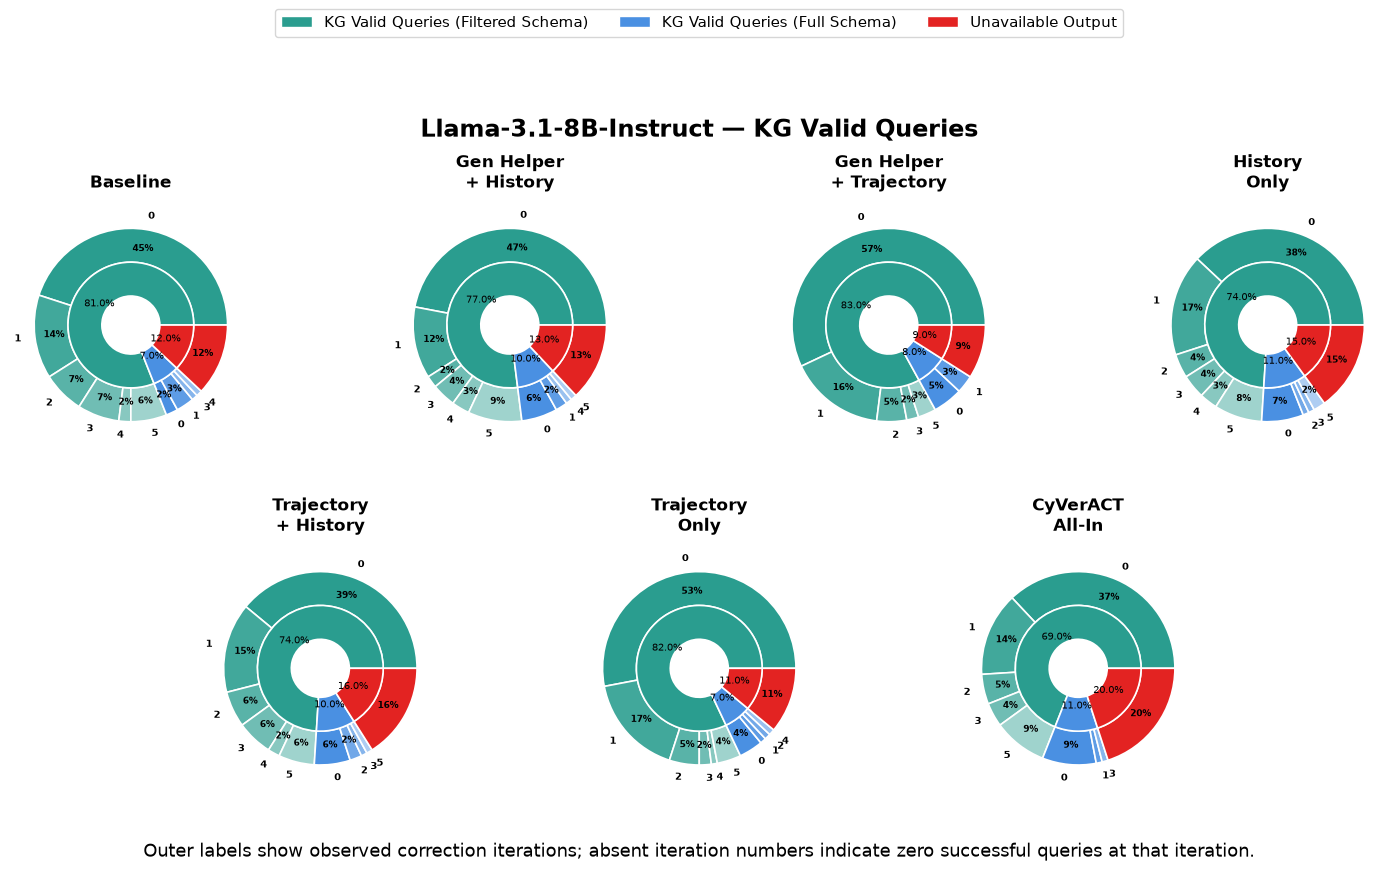

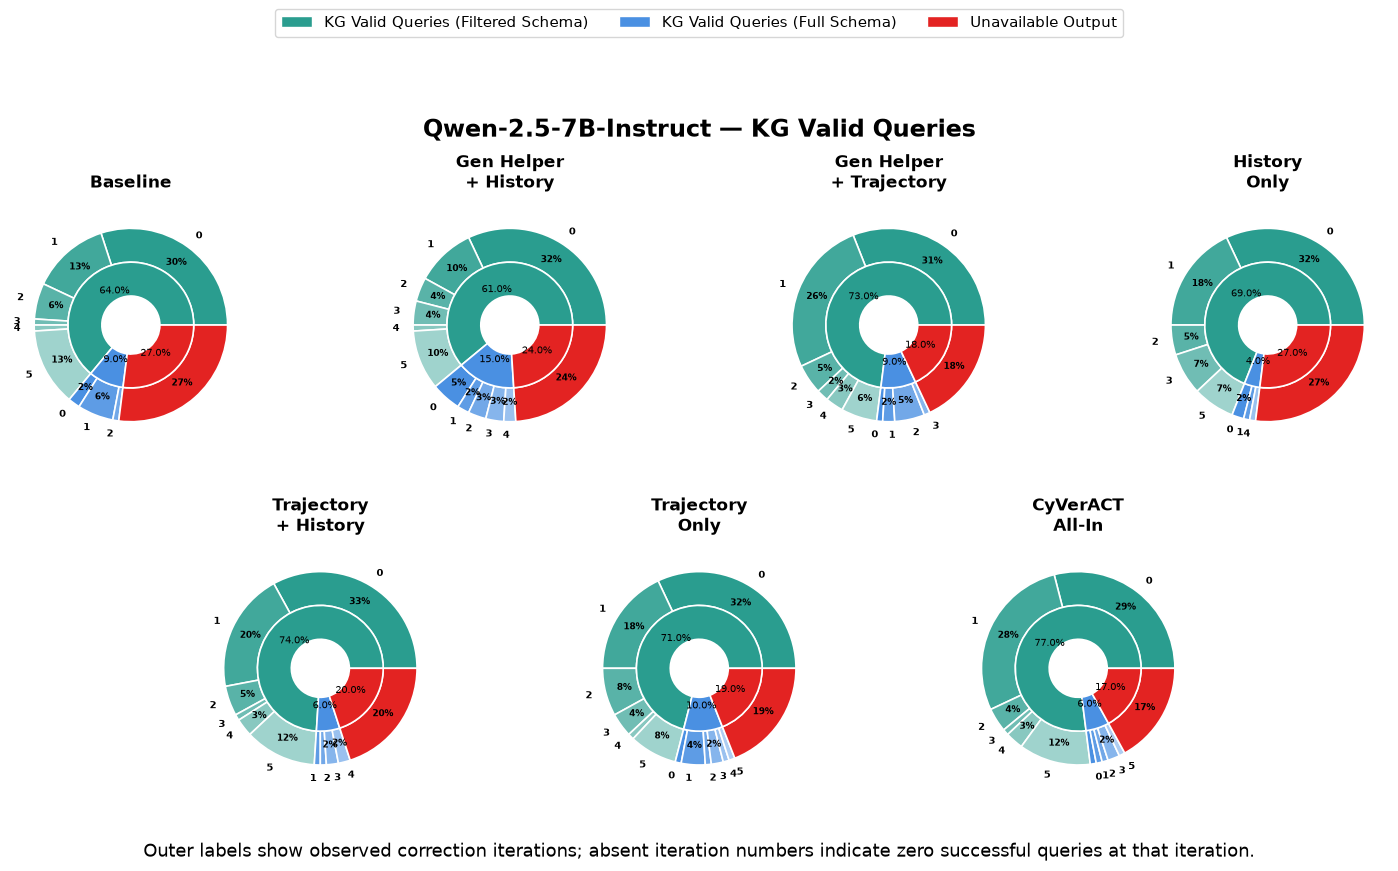

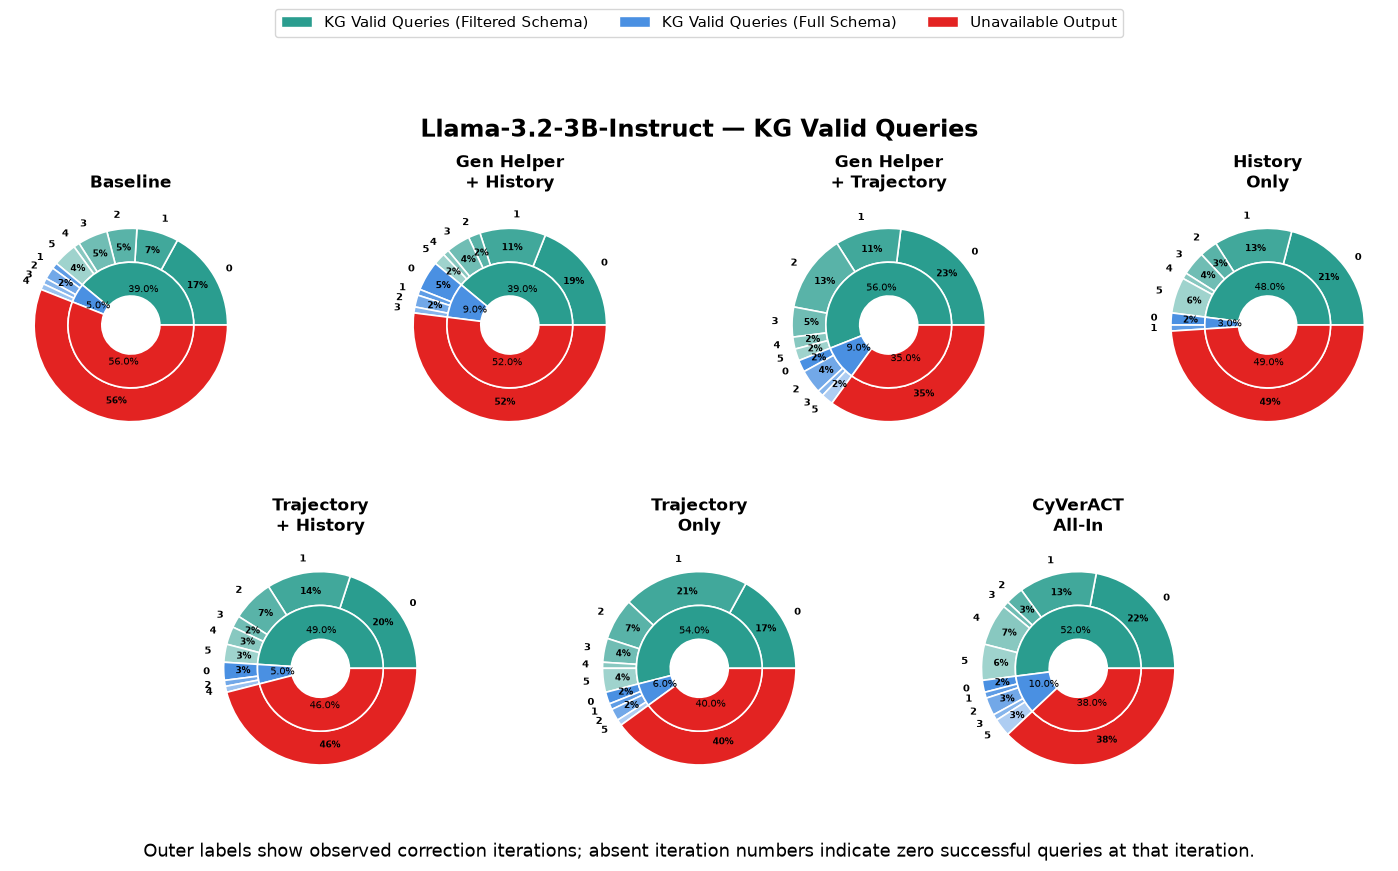

In [14]:
KG_FILTERED = 'KG Valid Queries (Filtered Schema)'
KG_FULL = 'KG Valid Queries (Full Schema)'
KG_UNAVAILABLE = 'Unavailable Output'

kg_categories = [KG_FILTERED, KG_FULL, KG_UNAVAILABLE]

kg_colors = {
    KG_FILTERED: COLOR_FILTERED,
    KG_FULL: COLOR_FULL,
    KG_UNAVAILABLE: COLOR_UNAVAILABLE
}

kg_legend = [
    Patch(facecolor=kg_colors[KG_FILTERED], edgecolor='white', label=KG_FILTERED),
    Patch(facecolor=kg_colors[KG_FULL], edgecolor='white', label=KG_FULL),
    Patch(facecolor=kg_colors[KG_UNAVAILABLE], edgecolor='white', label=KG_UNAVAILABLE)
]

for model_key in model_order:

    fig = plt.figure(figsize=(16, 9))

    gs = fig.add_gridspec(
        2, 8,
        left=0.04,
        right=0.96,
        bottom=0.11,
        top=0.76,
        wspace=0.30,
        hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=kg_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=3,
        fontsize=11,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — KG Valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.855
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):

        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()

        df['PlotCategory'] = KG_UNAVAILABLE
        df.loc[df['SchemaPhase'] == 'Filtered', 'PlotCategory'] = KG_FILTERED
        df.loc[df['SchemaPhase'] == 'Full', 'PlotCategory'] = KG_FULL

        inner_sizes = []
        inner_colors = []

        for category in kg_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(kg_colors[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []

        for category in kg_categories:

            sub_df = df[df['PlotCategory'] == category]

            if sub_df.empty:
                continue

            if category == KG_UNAVAILABLE:
                outer_sizes.append(len(sub_df))
                outer_colors.append(kg_colors[category])
                outer_labels.append('')
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .sort_index()
            )

            for iteration, count in iteration_counts.items():
                outer_sizes.append(count)

                outer_colors.append(
                    get_iteration_color(
                        kg_colors[category],
                        iteration
                    )
                )

                outer_labels.append(str(iteration))

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            labeldistance=1.14,
            autopct=outer_autopct,
            pctdistance=0.80,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        _, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in inner_autotexts:
            text.set_fontsize(7)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5,
        0.035,
        'Outer labels show observed correction iterations; absent iteration numbers indicate zero successful queries at that iteration.',
        ha='center',
        fontsize=13
    )

    plt.savefig(
        f'Figures/kg_valid_{model_key}_ppt.pdf',
        bbox_inches='tight'
    )

    plt.show()

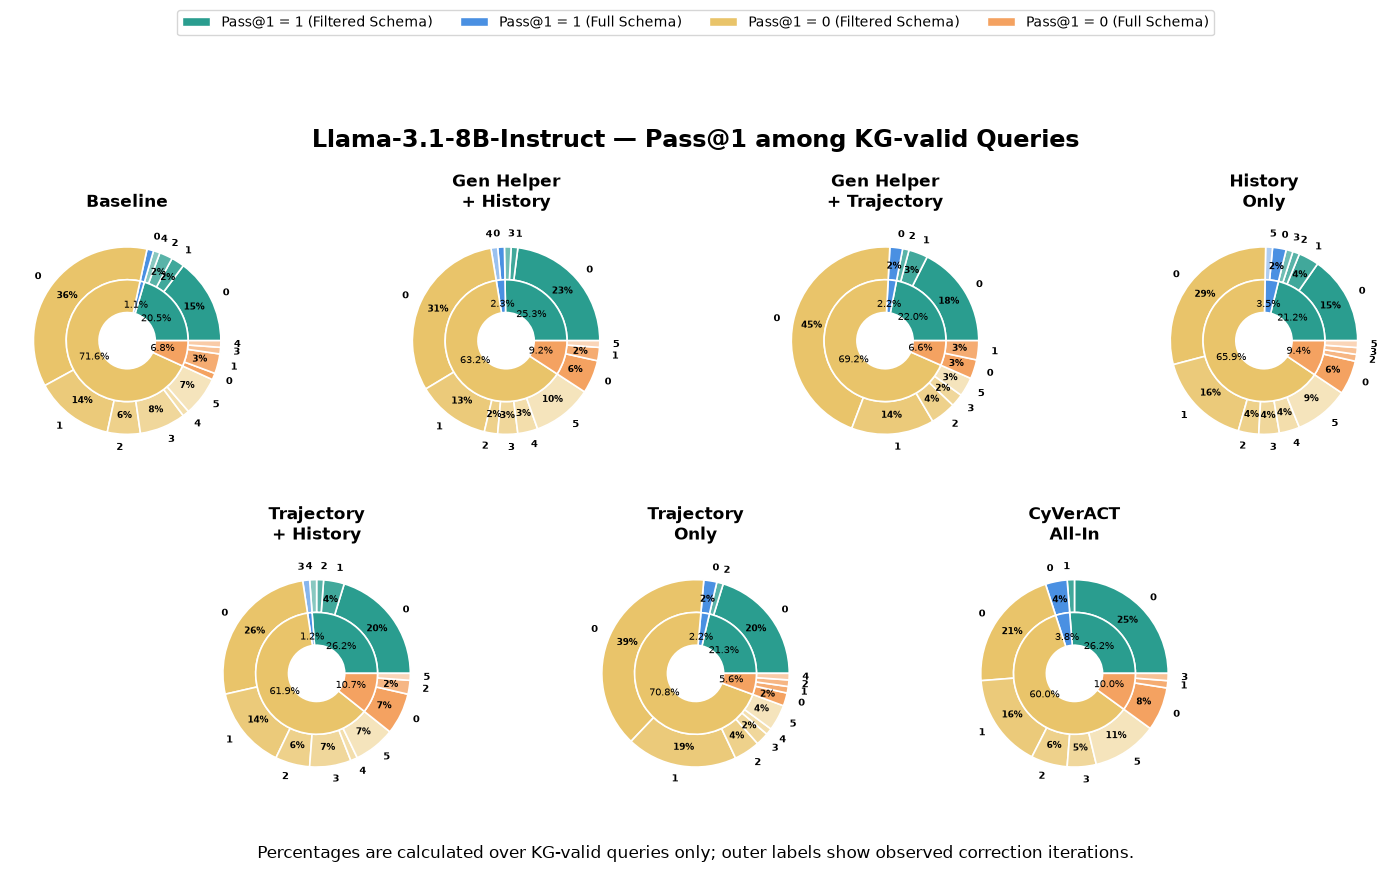

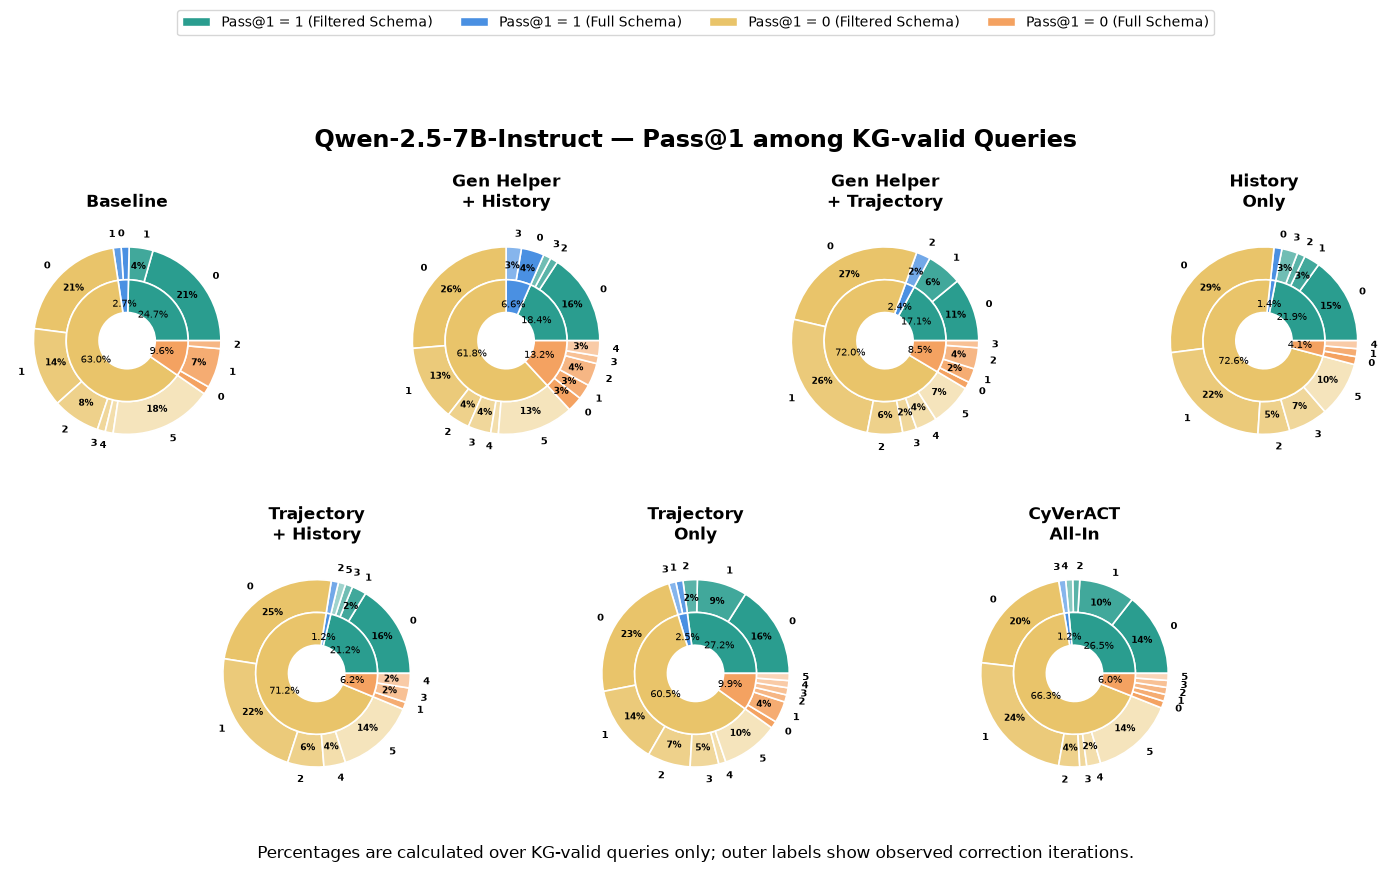

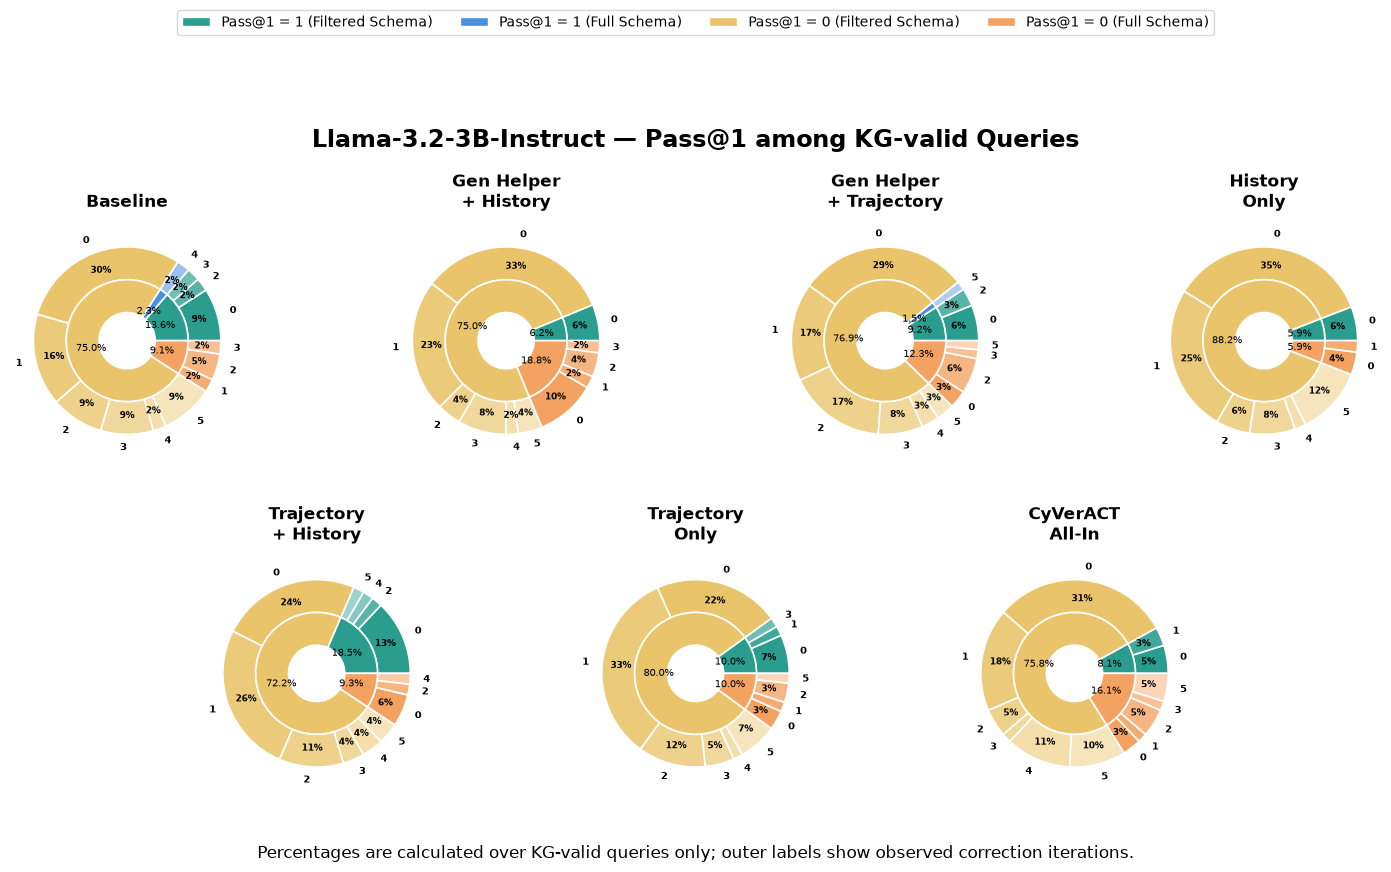

In [15]:
P1_FILTERED_SUCCESS = 'Pass@1 = 1 - Filtered'
P1_FULL_SUCCESS = 'Pass@1 = 1 - Full'
P1_FILTERED_FAIL = 'Pass@1 = 0 - Filtered'
P1_FULL_FAIL = 'Pass@1 = 0 - Full'

pass_categories = [
    P1_FILTERED_SUCCESS,
    P1_FULL_SUCCESS,
    P1_FILTERED_FAIL,
    P1_FULL_FAIL
]

pass_colors = {
    P1_FILTERED_SUCCESS: COLOR_FILTERED,
    P1_FULL_SUCCESS: COLOR_FULL,
    P1_FILTERED_FAIL: COLOR_FILTERED_FAIL,
    P1_FULL_FAIL: COLOR_FULL_FAIL
}

pass_legend = [
    Patch(facecolor=pass_colors[P1_FILTERED_SUCCESS], edgecolor='white', label='Pass@1 = 1 (Filtered Schema)'),
    Patch(facecolor=pass_colors[P1_FULL_SUCCESS], edgecolor='white', label='Pass@1 = 1 (Full Schema)'),
    Patch(facecolor=pass_colors[P1_FILTERED_FAIL], edgecolor='white', label='Pass@1 = 0 (Filtered Schema)'),
    Patch(facecolor=pass_colors[P1_FULL_FAIL], edgecolor='white', label='Pass@1 = 0 (Full Schema)')
]

for model_key in model_order:

    fig = plt.figure(figsize=(16, 9))

    gs = fig.add_gridspec(
        2, 8,
        left=0.04,
        right=0.96,
        bottom=0.11,
        top=0.74,
        wspace=0.30,
        hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=pass_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — Pass@1 among KG-valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.845
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):

        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()

        # Keep ONLY KG-valid queries
        df = df[
            df['SchemaPhase'].isin(['Filtered', 'Full'])
        ].copy()

        metric = pd.to_numeric(
            df['Pass@1 Output'],
            errors='coerce'
        ).fillna(0)

        df['PlotCategory'] = None

        df.loc[
            (df['SchemaPhase'] == 'Filtered') & metric.eq(1),
            'PlotCategory'
        ] = P1_FILTERED_SUCCESS

        df.loc[
            (df['SchemaPhase'] == 'Full') & metric.eq(1),
            'PlotCategory'
        ] = P1_FULL_SUCCESS

        df.loc[
            (df['SchemaPhase'] == 'Filtered') & metric.eq(0),
            'PlotCategory'
        ] = P1_FILTERED_FAIL

        df.loc[
            (df['SchemaPhase'] == 'Full') & metric.eq(0),
            'PlotCategory'
        ] = P1_FULL_FAIL

        inner_sizes = []
        inner_colors = []

        for category in pass_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(pass_colors[category])

        outer_sizes = []
        outer_colors = []
        outer_labels = []

        for category in pass_categories:

            sub_df = df[
                df['PlotCategory'] == category
            ]

            if sub_df.empty:
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .sort_index()
            )

            for iteration, count in iteration_counts.items():

                outer_sizes.append(count)

                outer_colors.append(
                    get_iteration_color(
                        pass_colors[category],
                        iteration
                    )
                )

                outer_labels.append(str(iteration))

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            labeldistance=1.14,
            autopct=outer_autopct,
            pctdistance=0.80,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        _, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in inner_autotexts:
            text.set_fontsize(7)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5,
        0.035,
        'Percentages are calculated over KG-valid queries only; outer labels show observed correction iterations.',
        ha='center',
        fontsize=12
    )

    plt.savefig(
        f'Figures/pass1_kg_valid_{model_key}_ppt.pdf',
        bbox_inches='tight'
    )

    plt.show()

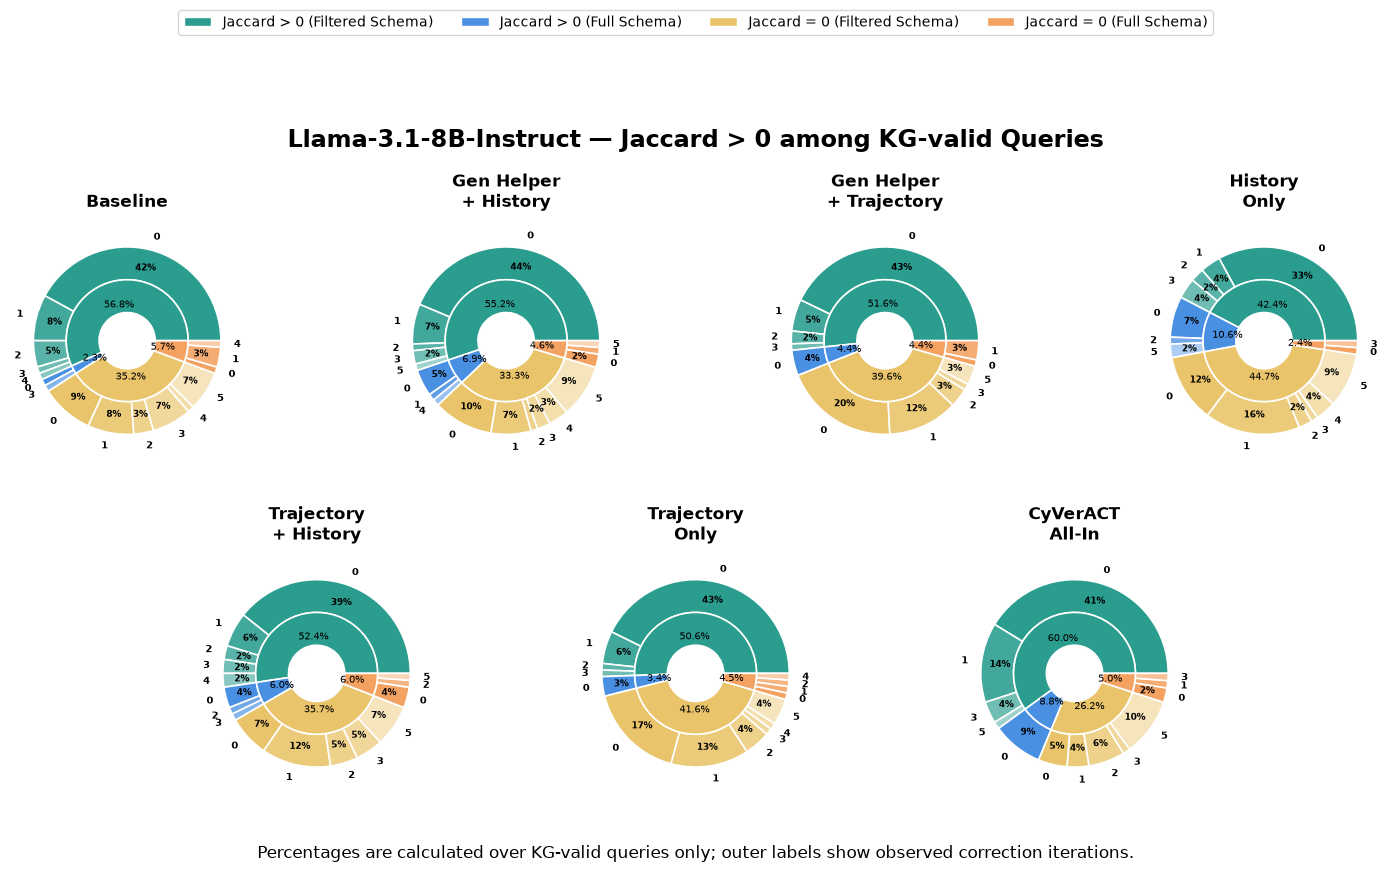

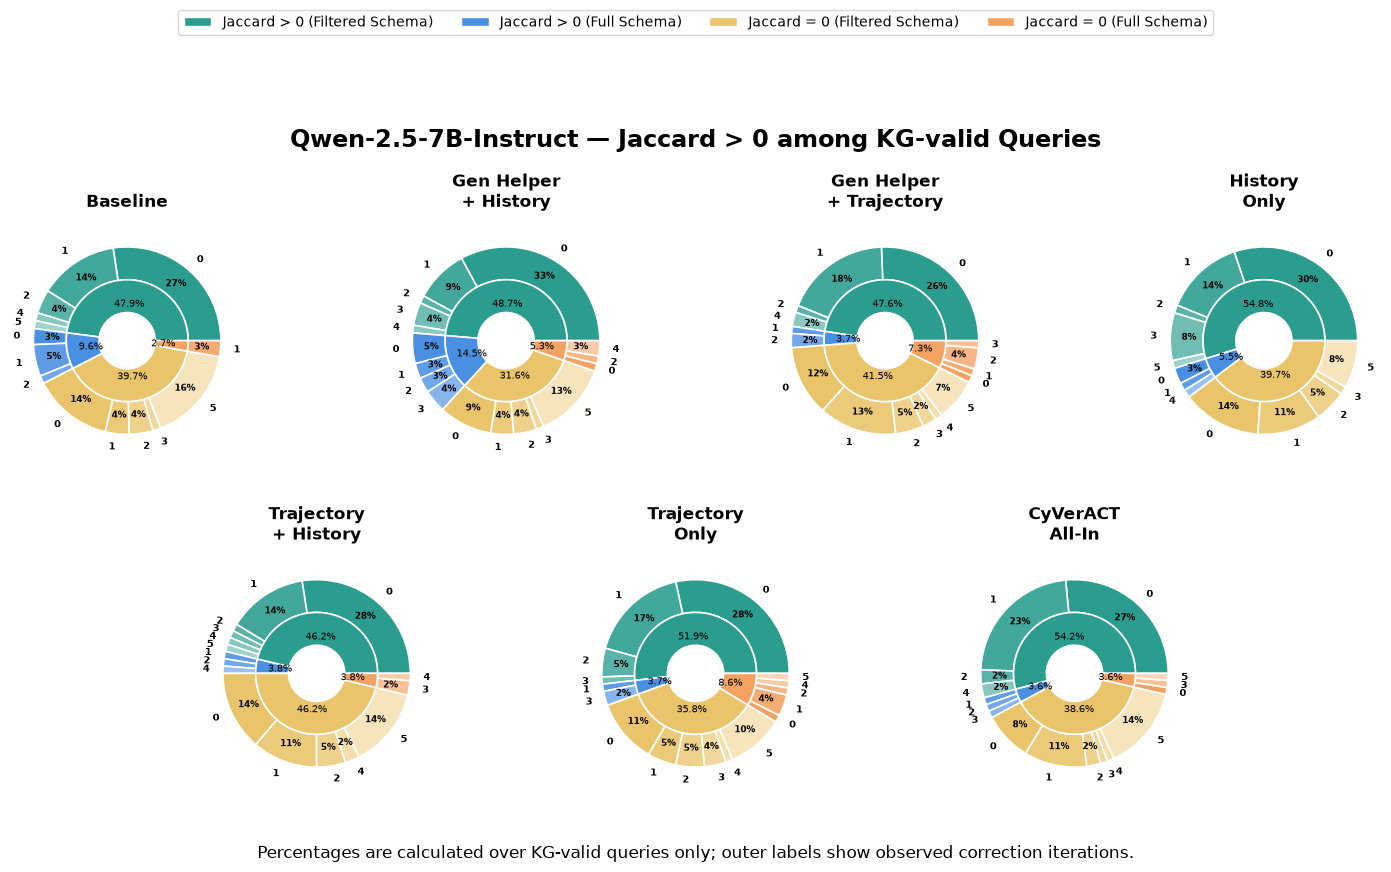

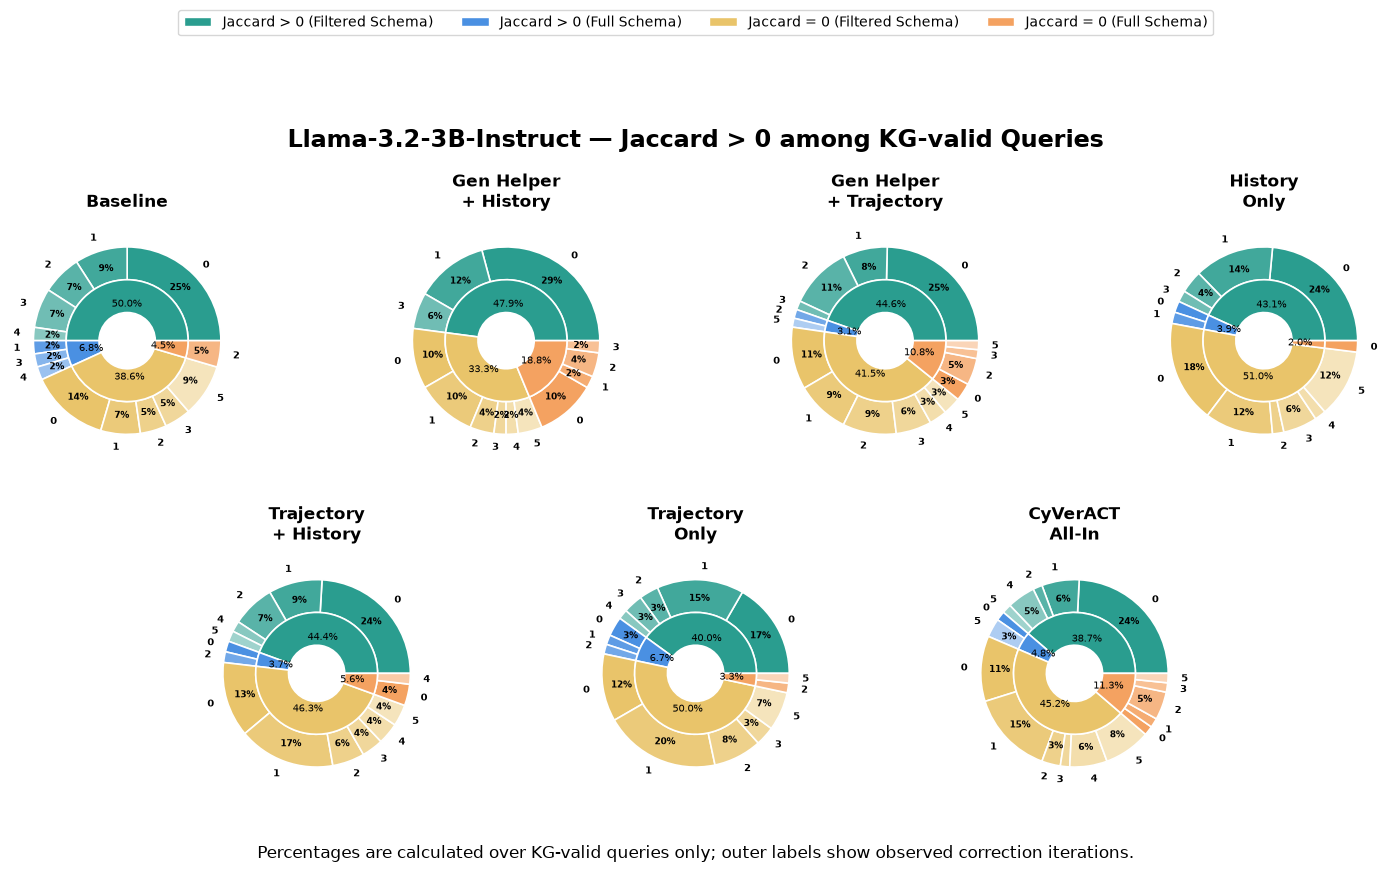

In [16]:
J_FILTERED_SUCCESS = 'Jaccard > 0 - Filtered'
J_FULL_SUCCESS = 'Jaccard > 0 - Full'
J_FILTERED_FAIL = 'Jaccard = 0 - Filtered'
J_FULL_FAIL = 'Jaccard = 0 - Full'

jaccard_categories = [
    J_FILTERED_SUCCESS,
    J_FULL_SUCCESS,
    J_FILTERED_FAIL,
    J_FULL_FAIL
]

jaccard_colors = {
    J_FILTERED_SUCCESS: COLOR_FILTERED,
    J_FULL_SUCCESS: COLOR_FULL,
    J_FILTERED_FAIL: COLOR_FILTERED_FAIL,
    J_FULL_FAIL: COLOR_FULL_FAIL
}

jaccard_legend = [
    Patch(facecolor=jaccard_colors[J_FILTERED_SUCCESS], edgecolor='white', label='Jaccard > 0 (Filtered Schema)'),
    Patch(facecolor=jaccard_colors[J_FULL_SUCCESS], edgecolor='white', label='Jaccard > 0 (Full Schema)'),
    Patch(facecolor=jaccard_colors[J_FILTERED_FAIL], edgecolor='white', label='Jaccard = 0 (Filtered Schema)'),
    Patch(facecolor=jaccard_colors[J_FULL_FAIL], edgecolor='white', label='Jaccard = 0 (Full Schema)')
]

for model_key in model_order:

    fig = plt.figure(figsize=(16, 9))

    gs = fig.add_gridspec(
        2, 8,
        left=0.04,
        right=0.96,
        bottom=0.11,
        top=0.74,
        wspace=0.30,
        hspace=0.42
    )

    axes = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[0, 6:8]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5]),
        fig.add_subplot(gs[1, 5:7])
    ]

    for ax in axes:
        ax.set_aspect('equal')

    fig.legend(
        handles=jaccard_legend,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.985),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    fig.suptitle(
        f'{model_names[model_key]} — Jaccard > 0 among KG-valid Queries',
        fontsize=17,
        fontweight='bold',
        y=0.845
    )

    ring_width = 0.35

    for idx, config_name in enumerate(config_order):

        ax = axes[idx]

        if config_name not in dfs[model_key]:
            ax.axis('off')
            continue

        df = dfs[model_key][config_name].copy()

        # Keep ONLY KG-valid queries
        df = df[
            df['SchemaPhase'].isin(['Filtered', 'Full'])
        ].copy()

        metric = pd.to_numeric(
            df['Jaccard Output'],
            errors='coerce'
        ).fillna(0)

        df['PlotCategory'] = None

        df.loc[
            (df['SchemaPhase'] == 'Filtered') & metric.gt(0),
            'PlotCategory'
        ] = J_FILTERED_SUCCESS

        df.loc[
            (df['SchemaPhase'] == 'Full') & metric.gt(0),
            'PlotCategory'
        ] = J_FULL_SUCCESS

        df.loc[
            (df['SchemaPhase'] == 'Filtered') & metric.eq(0),
            'PlotCategory'
        ] = J_FILTERED_FAIL

        df.loc[
            (df['SchemaPhase'] == 'Full') & metric.eq(0),
            'PlotCategory'
        ] = J_FULL_FAIL

        inner_sizes = []
        inner_colors = []

        for category in jaccard_categories:
            count = (df['PlotCategory'] == category).sum()

            if count > 0:
                inner_sizes.append(count)
                inner_colors.append(
                    jaccard_colors[category]
                )

        outer_sizes = []
        outer_colors = []
        outer_labels = []

        for category in jaccard_categories:

            sub_df = df[
                df['PlotCategory'] == category
            ]

            if sub_df.empty:
                continue

            iteration_counts = (
                sub_df['Iteration']
                .dropna()
                .astype(int)
                .value_counts()
                .sort_index()
            )

            for iteration, count in iteration_counts.items():

                outer_sizes.append(count)

                outer_colors.append(
                    get_iteration_color(
                        jaccard_colors[category],
                        iteration
                    )
                )

                outer_labels.append(str(iteration))

        _, outer_texts, outer_autotexts = ax.pie(
            outer_sizes,
            radius=1.0,
            colors=outer_colors,
            labels=outer_labels,
            labeldistance=1.14,
            autopct=outer_autopct,
            pctdistance=0.80,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in outer_texts:
            text.set_fontsize(7)
            text.set_weight('bold')

        for text in outer_autotexts:
            text.set_fontsize(6.5)
            text.set_weight('bold')

        _, _, inner_autotexts = ax.pie(
            inner_sizes,
            radius=1.0 - ring_width,
            colors=inner_colors,
            autopct='%1.1f%%',
            pctdistance=0.60,
            startangle=0,
            counterclock=True,
            wedgeprops=dict(
                width=ring_width,
                edgecolor='white',
                linewidth=1.2
            )
        )

        for text in inner_autotexts:
            text.set_fontsize(7)
            text.set_weight('normal')

        ax.set_title(
            config_names[config_name],
            fontsize=12,
            fontweight='bold',
            pad=12
        )

    fig.text(
        0.5,
        0.035,
        'Percentages are calculated over KG-valid queries only; outer labels show observed correction iterations.',
        ha='center',
        fontsize=12
    )

    plt.savefig(
        f'Figures/jaccard_kg_valid_{model_key}_ppt.pdf',
        bbox_inches='tight'
    )

    plt.show()

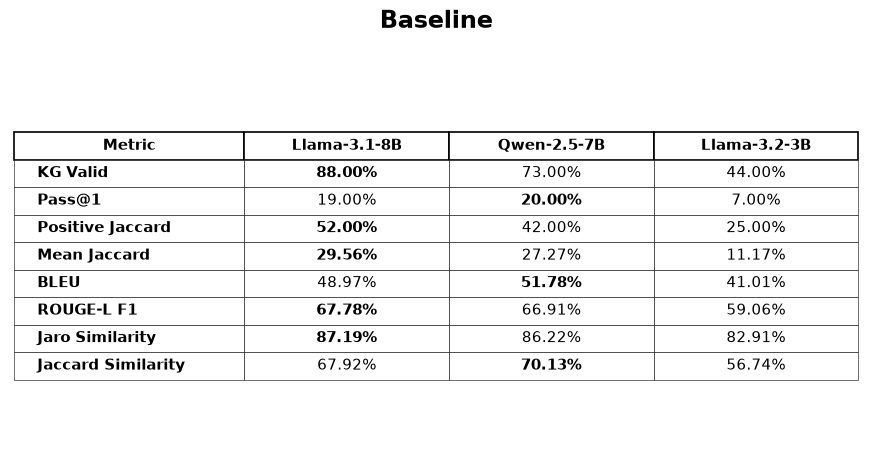

Saved: Figures/Metric_Tables/baseline_metrics.png


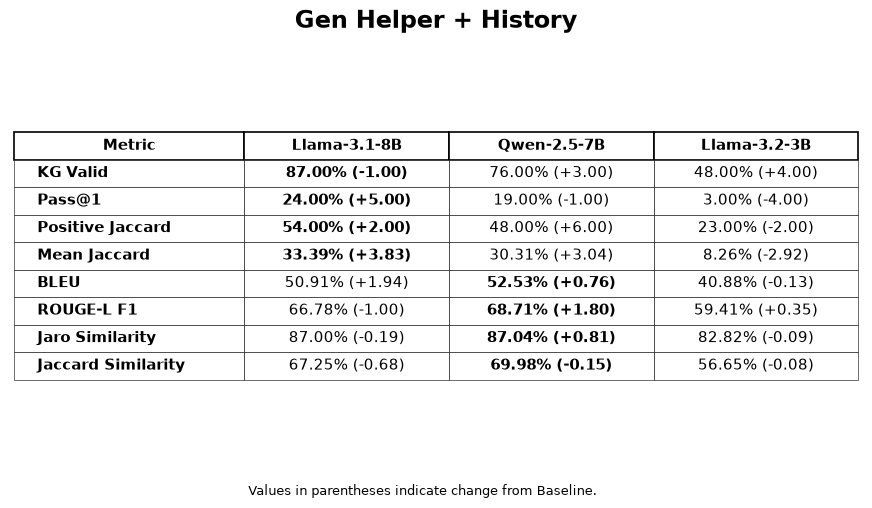

Saved: Figures/Metric_Tables/gen_helper_history_metrics.png


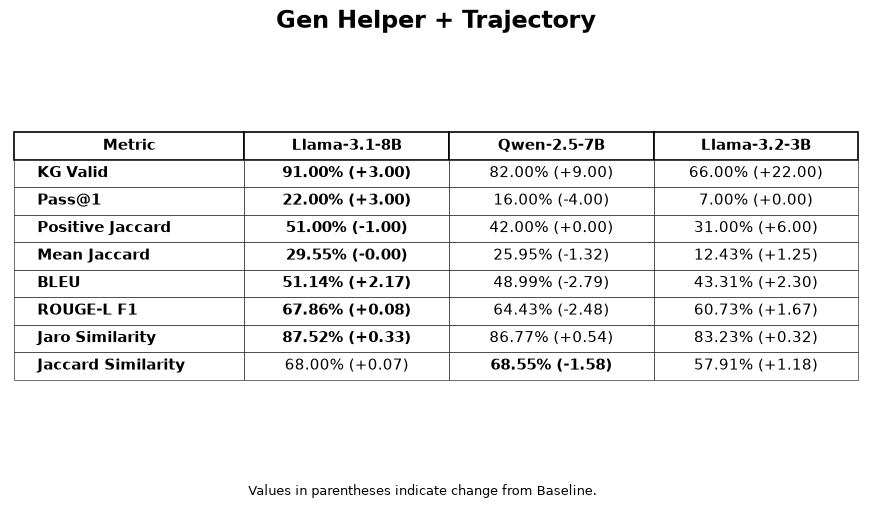

Saved: Figures/Metric_Tables/gen_helper_trajectory_metrics.png


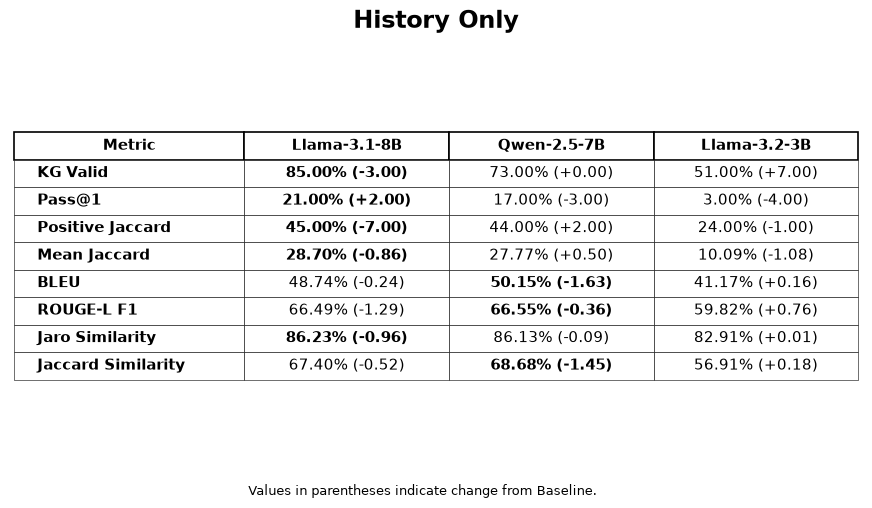

Saved: Figures/Metric_Tables/history_only_metrics.png


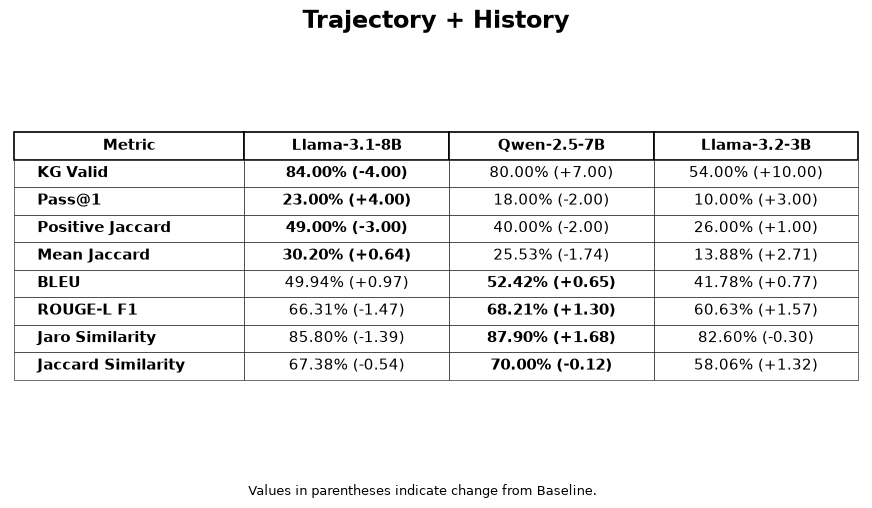

Saved: Figures/Metric_Tables/trajectory_history_metrics.png


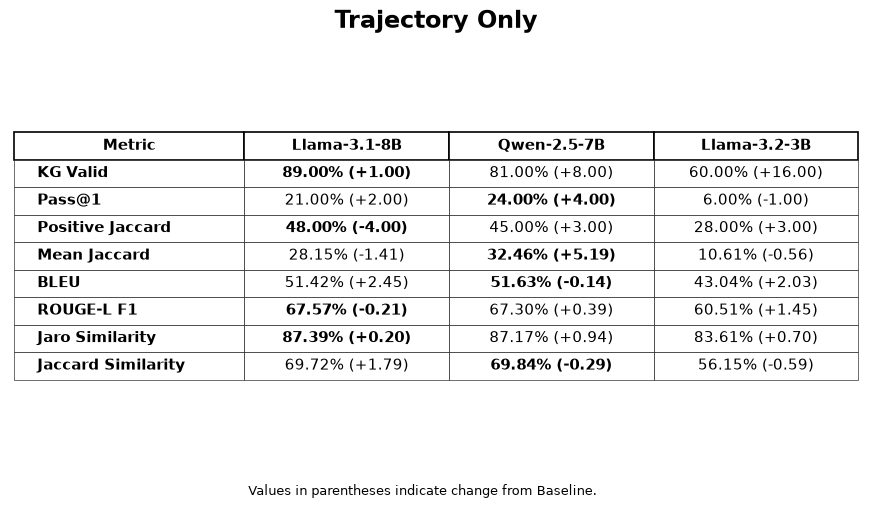

Saved: Figures/Metric_Tables/trajectory_only_metrics.png


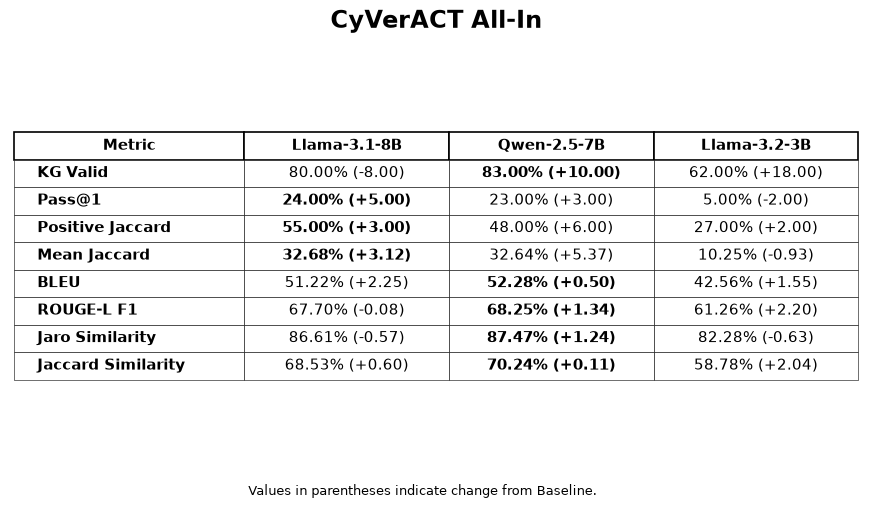

Saved: Figures/Metric_Tables/all_in_metrics.png


In [30]:
# ============================================================
# CREATE 7 SEPARATE TABLE IMAGES
# One image per configuration
# ============================================================

os.makedirs('Figures/Metric_Tables', exist_ok=True)

metric_display_names = {
    'KG Valid': 'KG Valid',
    'Pass@1': 'Pass@1',
    'Positive Jaccard': 'Positive Jaccard',
    'Mean Jaccard': 'Mean Jaccard',
    'BLEU': 'BLEU',
    'Rouge-L F1': 'ROUGE-L F1',
    'Jaro Similarity': 'Jaro Similarity',
    'Jaccard Similarity': 'Jaccard Similarity'
}

for config_name in config_order:

    # ========================================================
    # BUILD TABLE FOR THIS CONFIGURATION
    # ========================================================

    rows = []

    for metric in metrics_order:

        row = {
            'Metric': metric_display_names[metric]
        }

        for model_key in model_order:

            model_column = model_names[model_key]

            if config_name not in results[model_key]:
                row[model_column] = '—'
                continue

            value = results[model_key][config_name][metric]

            # ------------------------------------------------
            # BASELINE
            # Just show value
            # ------------------------------------------------

            if config_name == 'Baseline':

                row[model_column] = f'{value:.2f}%'

            # ------------------------------------------------
            # OTHER CONFIGURATIONS
            # Show value + difference from baseline
            # ------------------------------------------------

            else:

                baseline_value = (
                    results[model_key]['Baseline'][metric]
                )

                delta = value - baseline_value

                row[model_column] = (
                    f'{value:.2f}% ({delta:+.2f})'
                )

        rows.append(row)

    config_table = pd.DataFrame(rows)

    # ========================================================
    # CREATE FIGURE
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(11, 5.2)
    )

    ax.axis('off')

    # ========================================================
    # TITLE
    # ========================================================

    ax.set_title(
        config_names[config_name],
        fontsize=17,
        fontweight='bold',
        pad=20
    )

    # ========================================================
    # TABLE
    # ========================================================

    table = ax.table(
        cellText=config_table.values,
        colLabels=config_table.columns,
        cellLoc='center',
        colLoc='center',
        loc='center',
        colWidths=[
            0.27,   # Metric
            0.24,   # Llama-3.1-8B
            0.24,   # Qwen-2.5-7B
            0.24    # Llama-3.2-3B
        ]
    )

    table.auto_set_font_size(False)
    table.set_fontsize(10.5)
    table.scale(1, 1.65)

    # ========================================================
    # HEADER STYLE
    # ========================================================

    for col in range(len(config_table.columns)):

        cell = table[(0, col)]

        cell.set_text_props(
            weight='bold',
            fontsize=11
        )

        cell.set_linewidth(1.2)

    # ========================================================
    # BODY STYLE
    # ========================================================

    for row_idx in range(1, len(config_table) + 1):

        # Metric names aligned left
        table[
            (row_idx, 0)
        ].get_text().set_ha('left')

        table[
            (row_idx, 0)
        ].get_text().set_weight('bold')

        # Thin borders
        for col in range(len(config_table.columns)):

            table[
                (row_idx, col)
            ].set_linewidth(0.4)

    # ========================================================
    # BOLD BEST MODEL FOR EACH METRIC
    # within this configuration
    # ========================================================

    for metric_idx, metric in enumerate(metrics_order):

        values = {}

        for model_key in model_order:

            if config_name in results[model_key]:

                values[model_key] = (
                    results[model_key]
                    [config_name]
                    [metric]
                )

        if values:

            best_value = max(values.values())

            for model_idx, model_key in enumerate(model_order):

                if model_key not in values:
                    continue

                if np.isclose(
                    values[model_key],
                    best_value
                ):

                    # +1 because row 0 = header
                    table[
                        (metric_idx + 1, model_idx + 1)
                    ].get_text().set_weight('bold')

    # ========================================================
    # FOOTER
    # ========================================================

    if config_name == 'Baseline':

        footer = (
            ''
        )

    else:

        footer = (
            'Values in parentheses indicate change from Baseline.'
        )

    fig.text(
        0.5,
        0.035,
        footer,
        ha='center',
        fontsize=9
    )

    # ========================================================
    # SAVE IMAGE
    # ========================================================

    safe_name = (
        config_name
        .lower()
        .replace(' ', '_')
    )

    output_path = (
        f'Figures/Metric_Tables/'
        f'{safe_name}_metrics.png'
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches='tight',
        pad_inches=0.15
    )

    plt.show()

    print(f'Saved: {output_path}')

# END OF DIAGRAMS

In [2]:
from dotenv import load_dotenv
import os

from langchain_openai import ChatOpenAI

load_dotenv(override=True)

print("System Initialization")

if not os.getenv("OPENROUTER_API_KEY"):
    print("ERROR: OPENROUTER_API_KEY missing.")
elif not os.getenv("NEO4J_URI"):
    print("ERROR: NEO4J URI missing.")
else:
    print("Core API Keys found.")

# ----------------------------------------
# Model Settings
# ----------------------------------------

#model_name = "meta-llama/llama-3.1-8b-instruct"
#model_name = "meta-llama/llama-3.2-3b-instruct"
model_name = "qwen/qwen-2.5-7b-instruct"

print(f"\nInitializing OpenRouter model: {model_name}...")

try:

    model = ChatOpenAI(
        model=model_name,
        api_key=os.getenv("OPENROUTER_API_KEY"),
        base_url="https://openrouter.ai/api/v1",

        temperature=0.0,
        max_tokens=512,

        extra_body={
            "provider": {
                "allow_fallbacks": True,
            }
        }
    )

    print(f"Model {model_name} loaded successfully.")

except Exception as e:
    print(e)

print("\nSetup Complete! Ready for our agent!")

System Initialization
Core API Keys found.

Initializing OpenRouter model: qwen/qwen-2.5-7b-instruct...
Model qwen/qwen-2.5-7b-instruct loaded successfully.

Setup Complete! Ready for our agent!


In [3]:
import os
import time
import pandas as pd
import torch
from tqdm.auto import tqdm

def evaluate_model(model_name, model, target_file, save_to_memory=False):
    '''
    Evaluates the model using a specific Excel dataset.
    Uses the database connection information provided per row and passes 'save_to_memory'
    to prevent test data leakage during benchmark runs.
    '''

    # 1. Load target Excel file
    file_path = f"C:/Users/olgag/Desktop/agentic-memory/CyVerACT/extended_workflow/{target_file}"
    df = pd.read_excel(file_path)

    # 2. Setup output directories
    output_dir = f"Outputs_Evaluation/New_MultiDB_Experiment/{model_name}/"
    os.makedirs(output_dir, exist_ok=True)

    target_name = os.path.splitext(os.path.basename(target_file))[0]

    results_path_pkl = os.path.join(output_dir, f"{target_name}_{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{target_name}_{model_name}.xlsx")

    # 3. Resume progress if file already exists
    if os.path.exists(results_path_xlsx):
        print(f"Found existing progress at {results_path_xlsx}. Resuming...")
        df_results = pd.read_excel(results_path_xlsx).astype(object)
    else:
        df_results = df.copy().astype(object)

        new_cols = [
            'generated_cypher', 'answer', 'path', 'output',
            'cypher_errors_history', 'cypher_errors', 'is_KG_Valid_correct',
            'is_KG_Valid_correct_with_full_schema', 'total_tokens',
            'completion_tokens', 'prompt_tokens', 'eval_time_s', 'total_iterations'
        ]

        for col in new_cols:
            if col not in df_results.columns:
                df_results[col] = None

    config = {
        'configurable': {
            'model': model,
            'model_name': model_name,
            'attempts_w_filtered': 5,
            'total_attempts': 10
        },
        'recursion_limit': 50
    }

    print(f"Starting execution on {target_file} | Memory Saving: {save_to_memory}")

    # 4. Main evaluation loop
    pbar = tqdm(
        df_results.iterrows(),
        total=df_results.shape[0],
        desc="Evaluating queries",
        unit="query"
    )

    for i, row in pbar:
        pbar.set_postfix(
            db=row['database_name'],
            query=i
        )

        # Skip if already computed
        if pd.isna(row['generated_cypher']) or row['generated_cypher'] is None:

            # Identify question column
            question_text = row['question'] if 'question' in row else row['Question']

            # FOR MULTI DBs
            inputs = {
                'question': question_text,
                'database_url': row['url'],
                'database_name': row['database_name'],
                'database_user': row['username'],
                'database_password': row['password'],
                'iterations': 0,
                'save_to_memory': save_to_memory
            }

            # FOR MOVIES DB
            # inputs = {
            #     'question': question_text,
            #     'database_url': "neo4j://127.0.0.1:7687",
            #     'database_name': "movies",
            #     'database_user': "neo4j",
            #     'database_password': "agentmemory",
            #     'iterations': 0,
            #     'save_to_memory': save_to_memory  # Memory flag passed to graph
            # }

            result = None
            max_retries = 3

            # Robust Execution Retry Loop
            for attempt in range(max_retries):
                try:
                    start = time.perf_counter()
                    result = app.invoke(inputs, config=config)
                    elapsed = time.perf_counter() - start
                    break
                except Exception as e:
                    print(f"\nError on query {i} (Attempt {attempt+1}): {e}")
                    time.sleep(20)

            if result is None:
                continue

            # Extract Graph State Results
            path_list = result.get('path', [])
            is_valid_correct = result.get('is_KG_Valid_correct', False)

            # --- TEAM LOGIC: Calculate Full Schema Metric ---
            is_full_schema_correct = ('schema_retriever' in path_list) and bool(is_valid_correct)

            # 5. Store All Metrics
            df_results.at[i, 'eval_time_s'] = round(elapsed, 4)
            df_results.at[i, 'generated_cypher'] = result.get('cypher_statement', '')
            df_results.at[i, 'output'] = str(result.get('database_records', ''))
            df_results.at[i, 'path'] = str(path_list)
            df_results.at[i, 'cypher_errors'] = str(result.get('cypher_errors', []))
            df_results.at[i, 'cypher_errors_history'] = str(result.get('cypher_errors_history', []))
            df_results.at[i, 'is_KG_Valid_correct'] = is_valid_correct
            df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = is_full_schema_correct
            df_results.at[i, 'answer'] = result.get('answer', '')
            df_results.at[i, 'total_tokens'] = str(result.get('total_tokens', ''))
            df_results.at[i, 'prompt_tokens'] = str(result.get('prompt_tokens', ''))
            df_results.at[i, 'completion_tokens'] = str(result.get('completion_tokens', ''))
            df_results.at[i, 'total_iterations'] = result.get('iterations', 1)

            # Memory Cleanup
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            # Checkpoint Saves
            df_results.to_pickle(results_path_pkl)
            df_results.to_excel(results_path_xlsx, index=False)

            time.sleep(1) # Sleep delay for stability

        else:
            print(f"Skipping row {i}, already computed.")

    return df_results

In [ ]:
# POPULATE MEMORY (Memory Dataset) ---
model_name_mem = 'llama3_1_8b_'

df_memory_results = evaluate_model(
    model_name=model_name_mem, 
    model=model, 
    target_file='Multi_DBs_Datasets/250_memory_queries_thesis.xlsx',  
    save_to_memory=True                        
)

In [4]:
# Testing Dataset
model_name_mem = 'qwen2_5_7b_BASELINE'

df_memory_results = evaluate_model(
    model_name=model_name_mem, 
    model=model, 
    target_file='Multi_DBs_Datasets/500_test_queries_thesis.xlsx',  
    save_to_memory=False                        
)

Found existing progress at Outputs_Evaluation/New_MultiDB_Experiment/qwen2_5_7b_BASELINE/500_test_queries_thesis_qwen2_5_7b_BASELINE.xlsx. Resuming...
Starting execution on Multi_DBs_Datasets/500_test_queries_thesis.xlsx | Memory Saving: False


Evaluating queries:   0%|          | 0/500 [00:00<?, ?query/s]

Skipping row 0, already computed.
Skipping row 1, already computed.
Skipping row 2, already computed.
Skipping row 3, already computed.
Skipping row 4, already computed.
Skipping row 5, already computed.
Skipping row 6, already computed.
Skipping row 7, already computed.
Skipping row 8, already computed.
Skipping row 9, already computed.
Skipping row 10, already computed.
Skipping row 11, already computed.
Skipping row 12, already computed.
Skipping row 13, already computed.
Skipping row 14, already computed.
Skipping row 15, already computed.
Skipping row 16, already computed.
Skipping row 17, already computed.
Skipping row 18, already computed.
Skipping row 19, already computed.
Skipping row 20, already computed.
Skipping row 21, already computed.
Skipping row 22, already computed.
Skipping row 23, already computed.
Skipping row 24, already computed.
Skipping row 25, already computed.
Skipping row 26, already computed.
Skipping row 27, already computed.
Skipping row 28, already compu

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SHIPPED` does not exist in database `northwind`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=18, offset=17>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 17, 'line': 1, 'column': 18}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (:Order)-[:SHIPPED]->(shipEvent)\nWITH DISTINCT labels(shipEvent) AS shipEvent_labels\nUNWIND shipEvent_labels AS shipEvent\nRETURN DISTINCT shipEvent'
Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. Th


[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- Neo.ClientError.Statement.SyntaxError: Invalid input '}': expected ':' (line 1, column 392 (offset: 391))


- Neo.ClientNotification.Statement.UnknownRelationshipTypeWarning: One of the relationship types in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing relationship type is: SHIPPED)

Cypher Corrector: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (o:Order)-[:ORDERS]->(ord:ORDERS) WHERE o.shippedDate = ord.shippedDate RETURN o.orderID, o.shipName:


...


[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- Neo.ClientNotification.Statement.ParameterNotProvided: Did not supply query with enough parameters. The produced query plan will not be cached and is not executable without EXPLAIN. (Missing parameters: avgRuntime)

Cypher Corrector: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (d:Director)-[:DIRECTED]->(m:Movie)
WITH d, AVG(m.runtime) AS avgRuntime
MATCH (d)-[:DIRECTED]->(m:Movie {runtime: > avgRuntime})
RETURN d.name:

[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- Neo.ClientError.Statement.SyntaxError: Invalid input '>': expected an expression (line 3, column 43 (offset: 129))
"MATCH (d)-[:DIRECTED]->(m:Movie {runtime: > avgRuntime})"
                                           ^

Cypher Corrector: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (d:Director)-[:DIRECTED]->(m:Movie)
WITH d, AVG(m.runtime) 

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `month` does not exist in database `recommendations`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=45, offset=44>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 44, 'line': 1, 'column': 45}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'RETURN exists { MATCH (x:Director) WHERE (x.month) IS NOT NULL} AS exists'
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `day` does not exist in database `recommendations`. Verify that the spelling is correct


[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- Neo.ClientError.Statement.SyntaxError: Invalid input ')': expected an expression, ',' or '}' (line 1, column 72 (offset: 71))


- Neo.ClientNotification.Statement.UnknownPropertyKeyWarning: One of the property names in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing property name is: month)

- Neo.ClientNotification.Statement.UnknownPropertyKeyWarning: One of the property names in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing property name is: day)

- InvalidPropertyAccessByLabelWarning: The label Director does not have the following properties:  month, year, day.

Cypher Corrector: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (d

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `m1` does not exist in database `recommendations`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=42, offset=41>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 41, 'line': 1, 'column': 42}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'RETURN exists { MATCH (x:Movie) WHERE (x.m1) IS NOT NULL} AS exists'



[MEMORY MANAGER] save_to_memory is FALSE. Skipping error recording.

CyVer Errors from generated query:
- Neo.ClientError.Statement.SyntaxError: Invalid input '>': expected '-' (line 1, column 74 (offset: 73))


- Neo.ClientNotification.Statement.UnknownPropertyKeyWarning: One of the property names in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing property name is: m1)

- InvalidPropertyAccessByLabelWarning: The label Movie does not have the following properties:  m1.

Cypher Corrector: START
CyVer Evaluator: START
CyVer Evaluation of MATCH (m:Movie)-[:IN_GENRE]->(g:Genre)
WITH m WHERE m.imdbRating = (SELECT MAX(m1.imdbRating) FROM (MATCH (m1:Movie) RETURN m1.imdbRating))
RETURN m.title, m.year
UNION
MATCH (m:Movie)-[:IN_GENRE]->(g:Genre)
WHERE m.imdbRating = (SELECT MAX(m1.imdbRating) FROM (MATCH (m1:Movie) RETURN m1.imdbRating))
RETURN m.title, m.year:

[MEMORY 

In [ ]:
def evaluate_model (model_name, model, dataset):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Save the dataframe with the questions and the generated cypher queries to the Outputs_Evaluation folder.
    Return the dataframe
    '''
    # torch.cuda.empty_cache()#clear gpu cache
    # Get datasets 
    if dataset =='sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx',sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    # Create the directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}.xlsx")
   
    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        df_results = pd.read_excel(results_path_xlsx)
    else:# Run model on dataset
        df_results = df.copy() # Copy of the df with questions and expected answers, to add the answers of the llm 
        # Now define additional columns in df_results to store LLM results:
        df_results['generated_cypher'] = None 
        df_results['answer'] = None
        df_results['path'] = None           # Use None so we can store a list
        df_results['output'] = None           # Use None so we can store a list
        df_results['cypher_errors_history'] = None           # Use None so we can store a list
        df_results['cypher_errors'] = None           # Use None so we can store a list
        df_results['is_KG_Valid_correct'] = None           # Use None so we can store a list
        df_results['total_tokens'] = None           # Use None so we can store a list
        df_results['completion_tokens'] = None           # Use None so we can store a list
        df_results['prompt_tokens'] = None           # Use None so we can store a list

    config = {'configurable': {'model': model, 'model_name':model_name, 'attempts_w_filtered':5, 'total_attempts':10},'recursion_limit':50}
    
    print(f'Starting evaluation for {model_name} on {dataset} ...')
    # Iterate over each row and compute only if not already done
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            print(i,question)
            
            # Get credentials
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                #its the sustain dataset
                database_url = os.getenv('database_url')
                database_name = os.getenv('database_name')
                database_user = os.getenv('database_user')
                database_password = os.getenv('database_password')
                # activate it for gemma 9b
                # if database_name == 'offshoreleaks':
                #     print(f'Skipping row {i}, to avoid memory error in {database_name}')
                #     continue
                # else:# Configuration 
                inputs = {
                    'question':question,
                    'database_url': database_url,
                    'database_name':database_name,
                    'database_user':database_user,
                    'database_password':database_password
                }
                # torch.cuda.empty_cache() #clear gpu cache
            
                # Run the graph and save outputs
                result =app.invoke(inputs, config =config) #,debug=False
                df_results.at[i, 'generated_cypher'] = result['cypher_statement']
                df_results.at[i, 'output'] = str(result['database_records'])
                df_results.at[i, 'path'] = result['path']
                df_results.at[i, 'cypher_errors'] = result['cypher_errors']
                df_results.at[i, 'cypher_errors_history'] = result['cypher_errors_history']
                df_results.at[i, 'is_KG_Valid_correct'] = result['is_KG_Valid_correct']
                df_results.at[i, 'answer'] = result['answer']
                df_results.at[i, 'total_tokens'] = result['total_tokens']
                df_results.at[i, 'completion_tokens'] = result['completion_tokens']
                df_results.at[i, 'prompt_tokens'] = result['prompt_tokens']
                if ('schema_retriever' in result['path']) and result['is_KG_Valid_correct']:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
                else:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                torch.cuda.empty_cache()#clear gpu cache
                
                # Save results
                df_results.to_pickle(results_path_pkl)
                df_results.to_excel(results_path_xlsx, index=False)# Set index=False to exclude the index column in Excel
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results

In [ ]:
model_name = 'llama3_2_3b'
df_results = evaluate_model (model_name, models[model_name](), 'benchmark2025')

# Evaluate with computational metrics

In [2]:
def evaluate_model_usage (model_name, model, dataset):
    ''' 
    Evaluate the selected model on the given dataset, by invoking the graph workflow.
    Save the dataframe with the questions and the generated cypher queries to the Outputs_Evaluation folder.
    Return the dataframe
    '''
    # torch.cuda.empty_cache()#clear gpu cache
    # Get datasets 
    if dataset =='sustain':
        df = pd.read_excel('../data/text2cypher-sustaingraph/sustaintest.xlsx',sheet_name='Queries')
        subfolder = 'SustainDataset'
    elif dataset == 'benchmark2025':
        df = pd.read_excel('../data/text2cypher-2025v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2025'
    elif dataset == 'benchmark2024':
        df = pd.read_excel('../data/text2cypher-2024v1/test.xlsx')
        #update df only with rows with a database access
        df = df[df['url'].notna()].reset_index(drop=True)
        subfolder = 'BenchmarkDataset2024'
    
    output_dir = f"Outputs_Evaluation/{subfolder}/{model_name}/"
    # Create the directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    results_path_pkl = os.path.join(output_dir, f"{model_name}_usage1.pkl")
    results_path_xlsx = os.path.join(output_dir, f"{model_name}_usage1.xlsx")
   
    # Check if results file already exists
    if os.path.exists(results_path_xlsx):
        df_results = pd.read_excel(results_path_xlsx)
    else:# Run model on dataset
        df_results = df.copy() # Copy of the df with questions and expected answers, to add the answers of the llm 
        # Now define additional columns in df_results to store LLM results:
        df_results['generated_cypher'] = None 
        df_results['answer'] = None
        df_results['path'] = None           # Use None so we can store a list
        df_results['output'] = None           # Use None so we can store a list
        df_results['cypher_errors_history'] = None           # Use None so we can store a list
        df_results['cypher_errors'] = None           # Use None so we can store a list
        df_results['is_KG_Valid_correct'] = None           # Use None so we can store a list
        # timing columns
        df_results['eval_time_s'] = None              # <-- total wall-clock time per query
        # tokens columns
        df_results['total_tokens'] = None           # Use None so we can store a list
        df_results['completion_tokens'] = None           # Use None so we can store a list
        df_results['prompt_tokens'] = None           # Use None so we can store a list
    config = {'configurable': {'model': model, 'model_name':model_name, 'attempts_w_filtered':5, 'total_attempts':10},'recursion_limit':50}
    
    print(f'Starting evaluation for {model_name} on {dataset} ...')
    # Iterate over each row and compute only if not already done
    for i, row in tqdm(df_results.iterrows(), total=df_results.shape[0]):
        if pd.isna(row['generated_cypher']):
            question = row['Question'] if dataset == 'sustain' else row['question']
            print(i,question)
            
            # Get credentials
            required_cols = {'database_name', 'url', 'username', 'password'}
            if required_cols.issubset(df_results.columns):
                database_url = row['url']
                database_name = row['database_name']
                database_user = row['username']
                database_password = row['password']
            else:
                #its the sustain dataset
                database_url = os.getenv('database_url')
                database_name = os.getenv('database_name')
                database_user = os.getenv('database_user')
                database_password = os.getenv('database_password')
                # activate it for gemma 9b
                # if database_name == 'offshoreleaks':
                #     print(f'Skipping row {i}, to avoid memory error in {database_name}')
                #     continue
                # else:# Configuration 
                inputs = {
                    'question':question,
                    'database_url': database_url,
                    'database_name':database_name,
                    'database_user':database_user,
                    'database_password':database_password
                }
                # torch.cuda.empty_cache() #clear gpu cache
            
                # Run the graph and save outputs
                start = time.perf_counter() # start wall-clock timer
                result =app.invoke(inputs, config =config) #,debug=False
                elapsed = time.perf_counter() - start # elapsed wall-clock time
                df_results.at[i, 'eval_time_s'] = round(elapsed, 4)
                df_results.at[i, 'generated_cypher'] = result['cypher_statement']
                df_results.at[i, 'output'] = str(result['database_records'])
                df_results.at[i, 'path'] = result['path']
                df_results.at[i, 'cypher_errors'] = result['cypher_errors']
                df_results.at[i, 'cypher_errors_history'] = result['cypher_errors_history']
                df_results.at[i, 'is_KG_Valid_correct'] = result['is_KG_Valid_correct']
                df_results.at[i, 'answer'] = result['answer']
                df_results.at[i, 'total_tokens'] = result['total_tokens']
                df_results.at[i, 'completion_tokens'] = result['completion_tokens']
                df_results.at[i, 'prompt_tokens'] = result['prompt_tokens']
                if ('schema_retriever' in result['path']) and result['is_KG_Valid_correct']:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = True
                else:
                    df_results.at[i, 'is_KG_Valid_correct_with_full_schema'] = False
                torch.cuda.empty_cache()#clear gpu cache
                

                # Save results
                df_results.to_pickle(results_path_pkl)
                df_results.to_excel(results_path_xlsx, index=False)# Set index=False to exclude the index column in Excel
        else:
            print(f"Skipping row {i}, already computed.")
            
    return df_results